In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

# Ingest primary datasets directly
daily_activity = pd.read_csv("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/raw/dailyActivity_merged.csv")
daily_sleep = pd.read_csv("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/raw/sleepDay_merged.csv")
hourly_steps = pd.read_csv("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/raw/hourlySteps_merged.csv")

print("Files loaded successfully!")

Files loaded successfully!


In [3]:
# 1. Dimensions check
print(f"daily_activity shape: {daily_activity.shape}")
print(f"daily_sleep shape:    {daily_sleep.shape}")
print(f"hourly_steps shape:   {hourly_steps.shape}")

# 2. Distinct participants count
print("\nUnique Users:")
print(f"daily_activity: {daily_activity['Id'].nunique()} users")
print(f"daily_sleep:    {daily_sleep['Id'].nunique()} users")
print(f"hourly_steps:   {hourly_steps['Id'].nunique()} users")

daily_activity shape: (940, 15)
daily_sleep shape:    (413, 5)
hourly_steps shape:   (22099, 3)

Unique Users:
daily_activity: 33 users
daily_sleep:    24 users
hourly_steps:   33 users


In [4]:
# Check for null values
print("Missing values in daily_activity:\n", daily_activity.isnull().sum())
print("\nMissing values in daily_sleep:\n", daily_sleep.isnull().sum())
print("\nMissing values in hourly_steps:\n", hourly_steps.isnull().sum())

# Inspect column types
print("\nColumn Data Types:")
print("daily_activity date column:", daily_activity['ActivityDate'].dtype)
print("daily_sleep date column:   ", daily_sleep['SleepDay'].dtype)
print("hourly_steps date column:  ", hourly_steps['ActivityHour'].dtype)

Missing values in daily_activity:
 Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

Missing values in daily_sleep:
 Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64

Missing values in hourly_steps:
 Id              0
ActivityHour    0
StepTotal       0
dtype: int64

Column Data Types:
daily_activity date column: object
daily_sleep date column:    object
hourly_steps date column:   object


In [5]:
print(f"Duplicates in daily_activity: {daily_activity.duplicated().sum()}")
print(f"Duplicates in daily_sleep:    {daily_sleep.duplicated().sum()}")
print(f"Duplicates in hourly_steps:   {hourly_steps.duplicated().sum()}")

Duplicates in daily_activity: 0
Duplicates in daily_sleep:    3
Duplicates in hourly_steps:   0


In [6]:
# 1. Remove duplicate records from daily_sleep
daily_sleep = daily_sleep.drop_duplicates()
print(f"daily_sleep shape after dropping duplicates: {daily_sleep.shape}")

# 2. Standardize column names to lowercase for cleaner querying
daily_activity.columns = daily_activity.columns.str.lower()
daily_sleep.columns = daily_sleep.columns.str.lower()
hourly_steps.columns = hourly_steps.columns.str.lower()

# 3. Convert date strings to datetime objects
daily_activity['activitydate'] = pd.to_datetime(daily_activity['activitydate'], format='%m/%d/%Y')
daily_sleep['sleepday'] = pd.to_datetime(daily_sleep['sleepday'], format='%m/%d/%Y %I:%M:%S %p')
hourly_steps['activityhour'] = pd.to_datetime(hourly_steps['activityhour'], format='%m/%d/%Y %I:%M:%S %p')

# 4. Feature Engineering: Day of week and sleep metrics
daily_activity['day_of_week'] = daily_activity['activitydate'].dt.day_name()
daily_sleep['day_of_week'] = daily_sleep['sleepday'].dt.day_name()

# Calculate time awake in bed (restlessness / latency)
daily_sleep['time_awake_in_bed'] = daily_sleep['totaltimeinbed'] - daily_sleep['totalminutesasleep']

# Extract hour of day for hourly steps
hourly_steps['hour'] = hourly_steps['activityhour'].dt.hour

# 5. Filter zero-activity anomalies (days where device was not worn / 0 steps recorded)
zero_step_count = (daily_activity['totalsteps'] == 0).sum()
print(f"Days with 0 steps recorded (device not worn): {zero_step_count}")

# Retain active wear days for accurate behavioral averages
daily_activity_cleaned = daily_activity[daily_activity['totalsteps'] > 0].copy()
print(f"daily_activity shape after removing zero-step anomalies: {daily_activity_cleaned.shape}")

daily_sleep shape after dropping duplicates: (410, 5)
Days with 0 steps recorded (device not worn): 77
daily_activity shape after removing zero-step anomalies: (863, 16)


In [7]:
# Align date column names for merging
daily_sleep_renamed = daily_sleep.rename(columns={'sleepday': 'activitydate'})

# Merge activity and sleep on participant id and date
merged_activity_sleep = pd.merge(
    daily_activity_cleaned, 
    daily_sleep_renamed, 
    on=['id', 'activitydate'], 
    how='inner'
)

print(f"Merged activity & sleep records shape: {merged_activity_sleep.shape}")
print(f"Distinct users with both activity and sleep data: {merged_activity_sleep['id'].nunique()}")
merged_activity_sleep.head(3)

Merged activity & sleep records shape: (410, 21)
Distinct users with both activity and sleep data: 24


,id,activitydate,totalsteps,totaldistance,trackerdistance,loggedactivitiesdistance,veryactivedistance,moderatelyactivedistance,lightactivedistance,sedentaryactivedistance,veryactiveminutes,fairlyactiveminutes,lightlyactiveminutes,sedentaryminutes,calories,day_of_week_x,totalsleeprecords,totalminutesasleep,totaltimeinbed,day_of_week_y,time_awake_in_bed
0,1503960366,2016-04-12,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985,Tuesday,1,327,346,Tuesday,19
1,1503960366,2016-04-13,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797,Wednesday,2,384,407,Wednesday,23
2,1503960366,2016-04-15,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745,Friday,1,412,442,Friday,30


In [8]:
# 1. Tidy up day of week columns in merged dataset
if 'day_of_week_y' in merged_activity_sleep.columns:
    merged_activity_sleep = merged_activity_sleep.drop(columns=['day_of_week_y'])
    merged_activity_sleep = merged_activity_sleep.rename(columns={'day_of_week_x': 'day_of_week'})

# 2. Key descriptive statistics for activity
activity_stats = daily_activity_cleaned[[
    'totalsteps', 'totaldistance', 'veryactiveminutes', 
    'fairlyactiveminutes', 'lightlyactiveminutes', 
    'sedentaryminutes', 'calories'
]].describe().round(2)

print("--- Daily Activity Summary Statistics ---")
display(activity_stats)

# 3. Key descriptive statistics for sleep
sleep_stats = daily_sleep[[
    'totalminutesasleep', 'totaltimeinbed', 'time_awake_in_bed'
]].describe().round(2)

print("\n--- Daily Sleep Summary Statistics ---")
display(sleep_stats)

# 4. User-Level Segmentation by Step Count
user_avg_steps = daily_activity_cleaned.groupby('id')['totalsteps'].mean().reset_index()

def categorize_user(steps):
    if steps >= 10000:
        return 'Highly Active (10k+ steps)'
    elif steps >= 7500:
        return 'Moderately Active (7.5k - 10k)'
    elif steps >= 5000:
        return 'Low Active (5k - 7.5k)'
    else:
        return 'Sedentary (< 5k steps)'

user_avg_steps['user_type'] = user_avg_steps['totalsteps'].apply(categorize_user)
segment_distribution = user_avg_steps['user_type'].value_counts(normalize=True).round(4) * 100

print("\n--- User Activity Distribution (%) ---")
print(segment_distribution)

--- Daily Activity Summary Statistics ---


,totalsteps,totaldistance,veryactiveminutes,fairlyactiveminutes,lightlyactiveminutes,sedentaryminutes,calories
count,863.00,863.00,863.00,863.00,863.00,863.00,863.00
mean,8319.39,5.98,23.02,14.78,210.02,955.75,2361.30
std,4744.97,3.72,33.65,20.43,96.78,280.29,702.71
min,4.00,0.00,0.00,0.00,0.00,0.00,52.00
25%,4923.00,3.37,0.00,0.00,146.50,721.50,1855.50
50%,8053.00,5.59,7.00,8.00,208.00,1021.00,2220.00
75%,11092.50,7.90,35.00,21.00,272.00,1189.00,2832.00
max,36019.00,28.03,210.00,143.00,518.00,1440.00,4900.00



--- Daily Sleep Summary Statistics ---


,totalminutesasleep,totaltimeinbed,time_awake_in_bed
count,410.00,410.00,410.00
mean,419.17,458.48,39.31
std,118.64,127.46,46.71
min,58.00,61.00,0.00
25%,361.00,403.75,17.00
50%,432.50,463.00,25.50
75%,490.00,526.00,40.00
max,796.00,961.00,371.00



--- User Activity Distribution (%) ---
user_type
Moderately Active (7.5k - 10k)    30.30
Low Active (5k - 7.5k)            27.27
Highly Active (10k+ steps)        21.21
Sedentary (< 5k steps)            21.21
Name: proportion, dtype: float64


In [9]:
# Correlations in merged dataset
corr_matrix = merged_activity_sleep[[
    'totalsteps', 'calories', 'sedentaryminutes', 
    'veryactiveminutes', 'totalminutesasleep', 'time_awake_in_bed'
]].corr().round(2)

print("--- Correlation Matrix ---")
display(corr_matrix)

--- Correlation Matrix ---


,totalsteps,calories,sedentaryminutes,veryactiveminutes,totalminutesasleep,time_awake_in_bed
totalsteps,1.00,0.41,-0.13,0.54,-0.19,0.03
calories,0.41,1.00,0.10,0.61,-0.03,-0.29
sedentaryminutes,-0.13,0.10,1.00,-0.02,-0.60,-0.17
veryactiveminutes,0.54,0.61,-0.02,1.00,-0.09,-0.08
totalminutesasleep,-0.19,-0.03,-0.60,-0.09,1.00,-0.00
time_awake_in_bed,0.03,-0.29,-0.17,-0.08,-0.00,1.00


In [10]:
import os

# Ensure the processed folder exists
os.makedirs("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/processed", exist_ok=True)

# Export clean, analysis-ready datasets
daily_activity_cleaned.to_csv("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/processed/daily_activity_cleaned.csv", index=False)
merged_activity_sleep.to_csv("C:/Users/sanju/Desktop/CaseStudies/Bellabeat_CS2/data/processed/merged_activity_sleep.csv", index=False)

print("Processed datasets exported successfully!")

Processed datasets exported successfully!


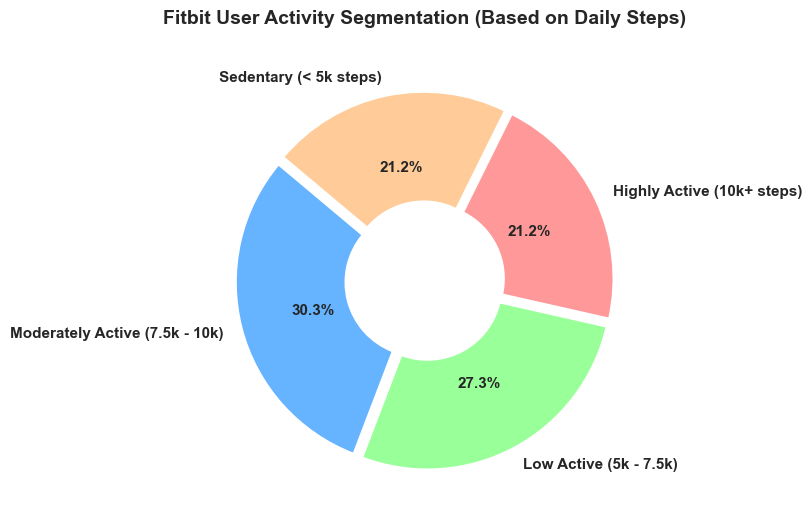

In [11]:
import os
os.makedirs("../visuals", exist_ok=True)

# Chart 1: User Activity Segmentation
plt.figure(figsize=(8, 8))
colors = ['#66b3ff', '#99ff99', '#ff9999', '#ffcc99']
explode = (0.03, 0.03, 0.03, 0.03)

plt.pie(
    segment_distribution, 
    labels=segment_distribution.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=explode, 
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11, 'weight': 'bold'}
)
plt.title("Fitbit User Activity Segmentation (Based on Daily Steps)", fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.savefig("../visuals/01_user_activity_distribution.png", dpi=300)
plt.show()

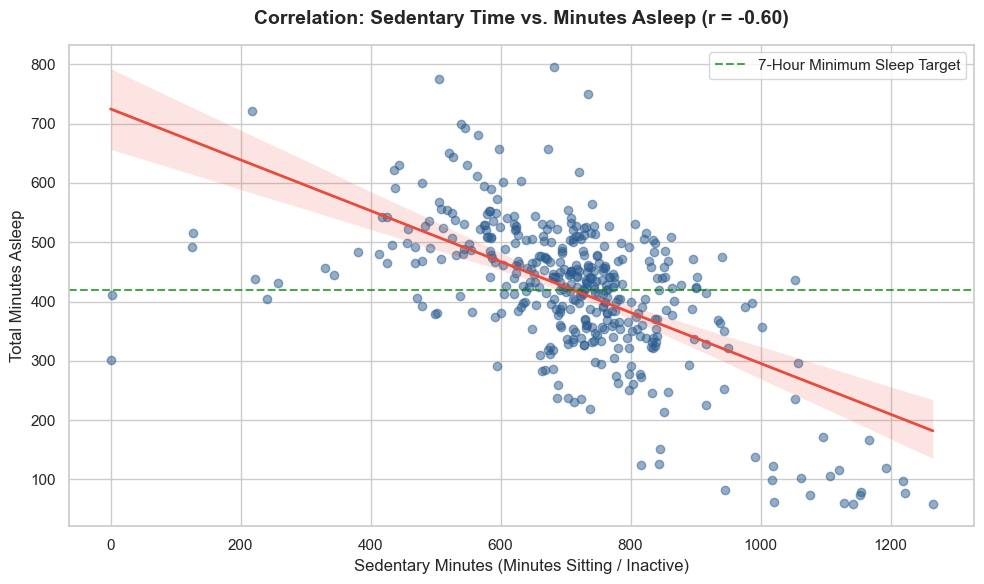

In [12]:
# Chart 2: Sedentary Minutes vs. Sleep Duration
plt.figure(figsize=(10, 6))
sns.regplot(
    data=merged_activity_sleep, 
    x='sedentaryminutes', 
    y='totalminutesasleep',
    scatter_kws={'alpha': 0.5, 'color': '#2b5c8f'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)
plt.title("Correlation: Sedentary Time vs. Minutes Asleep (r = -0.60)", fontsize=14, weight='bold', pad=15)
plt.xlabel("Sedentary Minutes (Minutes Sitting / Inactive)", fontsize=12)
plt.ylabel("Total Minutes Asleep", fontsize=12)
plt.axhline(420, color='green', linestyle='--', alpha=0.7, label='7-Hour Minimum Sleep Target')
plt.legend()
plt.tight_layout()
plt.savefig("../visuals/02_sedentary_vs_sleep.png", dpi=300)
plt.show()

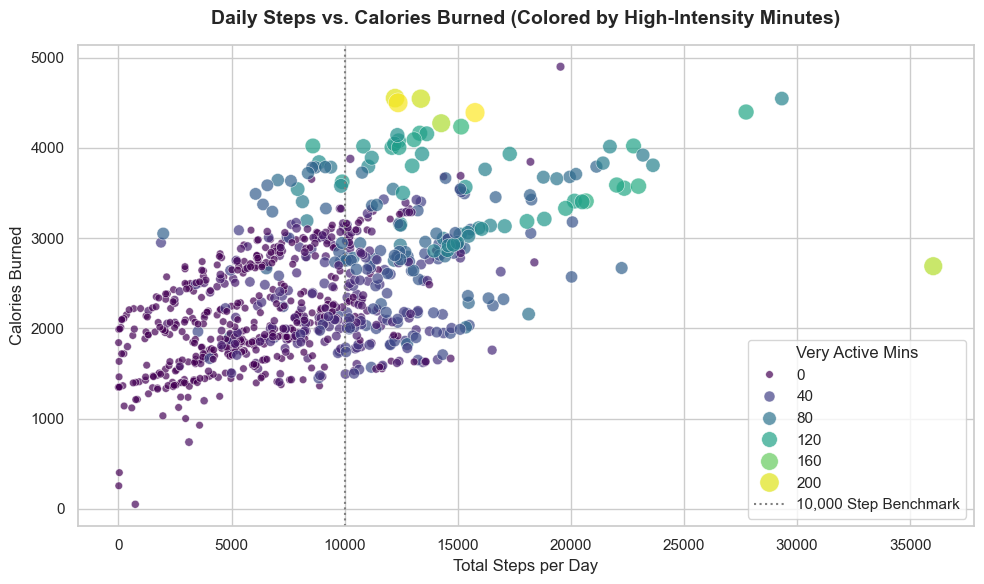

In [13]:
# Chart 3: Total Steps vs. Calories Burned
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(
    data=daily_activity_cleaned,
    x='totalsteps',
    y='calories',
    hue='veryactiveminutes',
    palette='viridis',
    size='veryactiveminutes',
    sizes=(30, 200),
    alpha=0.7
)
plt.title("Daily Steps vs. Calories Burned (Colored by High-Intensity Minutes)", fontsize=14, weight='bold', pad=15)
plt.xlabel("Total Steps per Day", fontsize=12)
plt.ylabel("Calories Burned", fontsize=12)
plt.axvline(10000, color='gray', linestyle=':', label='10,000 Step Benchmark')
plt.legend(title='Very Active Mins', loc='lower right')
plt.tight_layout()
plt.savefig("../visuals/03_steps_vs_calories.png", dpi=300)
plt.show()

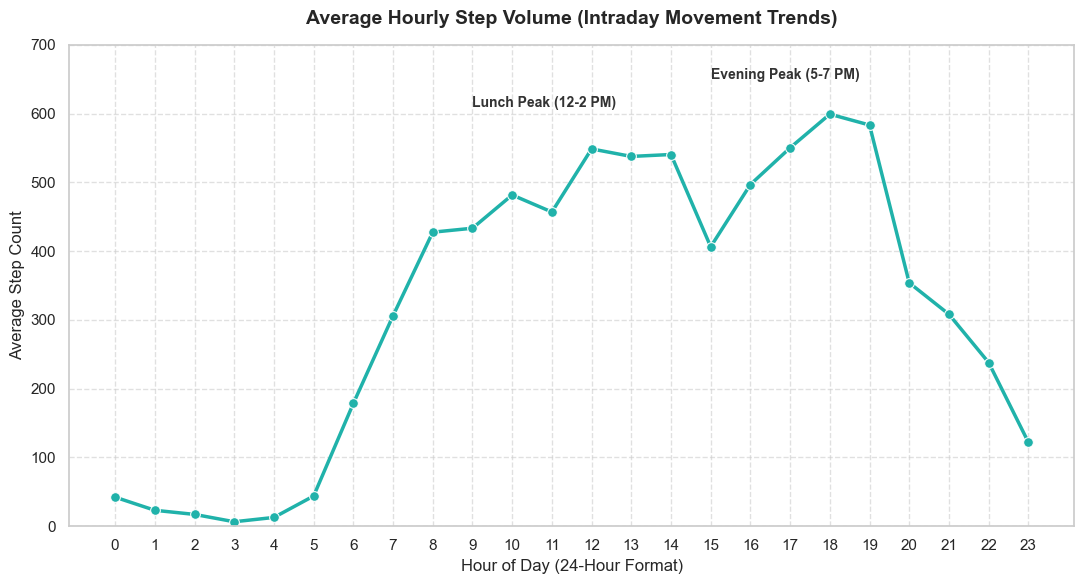

In [14]:
# Chart 4 (Polished): Hourly Step Cadence
hourly_avg = hourly_steps.groupby('hour')['steptotal'].mean().reset_index()

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=hourly_avg, 
    x='hour', 
    y='steptotal', 
    marker='o', 
    color='#20b2aa', 
    linewidth=2.5,
    markersize=7
)
plt.title("Average Hourly Step Volume (Intraday Movement Trends)", fontsize=14, weight='bold', pad=15)
plt.xlabel("Hour of Day (24-Hour Format)", fontsize=12)
plt.ylabel("Average Step Count", fontsize=12)
plt.xticks(range(0, 24))
plt.ylim(0, 700)  # Adds clean breathing room for annotations
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate peaks with proper offsets
lunch_val = hourly_avg.loc[hourly_avg['hour'] == 12, 'steptotal'].values[0]
evening_val = hourly_avg.loc[hourly_avg['hour'] == 18, 'steptotal'].values[0]

plt.annotate(
    'Lunch Peak (12-2 PM)', xy=(12, lunch_val),
    xytext=(9, 610), arrowprops=dict(facecolor='#333333', arrowstyle='->', lw=1.2),
    weight='bold', fontsize=10, color='#333333'
)
plt.annotate(
    'Evening Peak (5-7 PM)', xy=(18, evening_val),
    xytext=(15, 650), arrowprops=dict(facecolor='#333333', arrowstyle='->', lw=1.2),
    weight='bold', fontsize=10, color='#333333'
)

plt.tight_layout()
plt.savefig("../visuals/04_hourly_step_trends.png", dpi=300)
plt.show()